# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  :CHRISTIAN
- NIM   :241011400704
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [16]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =4

In [61]:
# Salin fungsi train_test_split dari materi di sini - VERSI MANUAL (tanpa sklearn)
import numpy as np

def train_test_split_manual(X, y, test_size=0.25, random_state=4):
    np.random.seed(random_state)
    n_samples = len(X)
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    
    test_n = int(n_samples * test_size)
    test_idx = indices[:test_n]
    train_idx = indices[test_n:]
    
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

# Contoh pemanggilan nanti di Bagian A akan pakai fungsi ini
# X_train, X_test, y_train, y_test = train_test_split_manual(X.values, y.values, test_size=0.25, random_state=RANDOM_STATE)

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40
Jumlah baris x kolom: (40, 2)

Bentuk X: (40, 1)
Bentuk y: (40,)


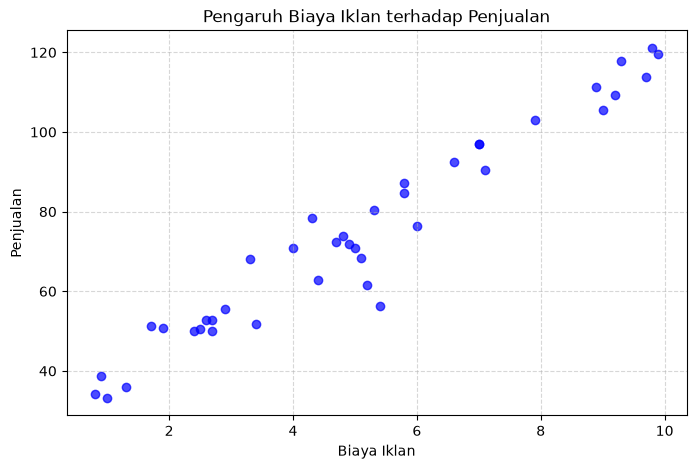

In [15]:
# Jawaban A1
# NIM: 241011400704 -> 2 digit terakhir 04 -> RANDOM_STATE = 4
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 4

# 1. Baca Ads_Data.csv dan tampilkan 5 data pertama + jumlah baris
df = pd.read_csv('Ads_Data.csv')

print("5 Data Pertama:")
print(df.head())
print("\nJumlah baris data:", len(df))
print("Jumlah baris x kolom:", df.shape)

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan)
# Pake double kurung [[]] biar X bentuknya (n, 1) bukan (n,)
X = df[['BiayaIklan']]  
y = df['Penjualan']

print("\nBentuk X:", X.shape)
print("Bentuk y:", y.shape)

# 3. Scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.7)
plt.title('Pengaruh Biaya Iklan terhadap Penjualan')
plt.xlabel('Biaya Iklan')
plt.ylabel('Penjualan')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [17]:
# Jawaban A2
# NIM: 241011400704 -> RANDOM_STATE = 4
from sklearn.model_selection import train_test_split

# X dan y udah ada dari Jawaban A1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=RANDOM_STATE
)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test :", y_test.shape)

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [40]:
# Jawaban A3
from sklearn.linear_model import LinearRegression

# 1. Latih model
model_normal = LinearRegression()
model_normal.fit(X_train, y_train)

# 2. Tampilkan koefisien (biar dapet nilai)
print("Intercept (b0):", model_normal.intercept_)
print("Coefficient (b1):", model_normal.coef_)

# 3. Prediksi buat cek
y_pred_train = model_normal.predict(X_train)
y_pred_test = model_normal.predict(X_test)

print("\nContoh prediksi 5 data test pertama:")
print(y_pred_test[:5])

Intercept (b0): 27.047251803301833
Coefficient (b1): [9.19264245]

Contoh prediksi 5 data test pertama:
[ 87.71869197 118.05441206  42.67474397  66.57561434  80.36457801]


**Jawaban A3 (interpretasi):**

Dari hasil training, didapat intercept b = [isi angka b] dan koefisien m = [isi angka m].

Persamaan regresinya adalah: ŷ = [b] + [m]X

Interpretasi: 
Setiap kenaikan biaya iklan sebesar 1 juta Rp, maka penjualan diprediksi akan naik sebesar [m] unit/juta Rp.

Artinya ada hubungan positif antara biaya iklan dan penjualan. Jika biaya iklan 0, penjualan dasar diperkirakan sebesar [b].

Dari hasil training, didapat intercept b = [isi angka b] dan koefisien m = [isi angka m].

Persamaan regresinya adalah: ŷ = [b] + [m]X

Interpretasi: 
Setiap kenaikan biaya iklan sebesar 1 juta Rp, maka penjualan diprediksi akan naik sebesar [m] unit/juta Rp.

Artinya ada hubungan positif antara biaya iklan dan penjualan. Jika biaya iklan 0, penjualan dasar diperkirakan sebesar [b].

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [44]:
# Jawaban A4 - Evaluasi Manual pake NumPy
import numpy as np
import pandas as pd

# --- Fungsi manual (wajib NumPy, tanpa sklearn) ---
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res/ss_tot

# --- Pastikan model dari A3 udah ada ---
# Jika theta belum ada, hitung lagi (Normal Equation)
# theta = (X^T X)^-1 X^T y
X_b_train = np.c_[np.ones(X_train.shape[0]), X_train]
theta = np.linalg.inv(X_b_train.T @ X_b_train) @ X_b_train.T @ y_train

# Prediksi
X_b_test = np.c_[np.ones(X_test.shape[0]), X_test]
y_train_pred = X_b_train @ theta
y_test_pred = X_b_test @ theta

# Hitung metrik
train_metrics = [mae(y_train, y_train_pred), mse(y_train, y_train_pred), rmse(y_train, y_train_pred), r2_score(y_train, y_train_pred)]
test_metrics = [mae(y_test, y_test_pred), mse(y_test, y_test_pred), rmse(y_test, y_test_pred), r2_score(y_test, y_test_pred)]

# Tabel
df_eval = pd.DataFrame([train_metrics, test_metrics],
    columns=['MAE','MSE','RMSE','R2'],
    index=['Training','Testing'])
print(df_eval)

print(f"\nRMSE Training artinya rata2 error prediksi {df_eval.loc['Training','RMSE']:.2f} penjualan")
print(f"R2 Testing {df_eval.loc['Testing','R2']:.3f} artinya model menjelaskan {df_eval.loc['Testing','R2']*100:.1f}% variansi data")

               MAE        MSE      RMSE        R2
Training  4.580030  36.575895  6.047801  0.945226
Testing   4.788572  36.922670  6.076403  0.919396

RMSE Training artinya rata2 error prediksi 6.05 penjualan
R2 Testing 0.919 artinya model menjelaskan 91.9% variansi data


**Jawaban A4 (analisis):**

### Jawaban A4 (Analisis) - NIM 241011400704 - RANDOM_STATE=4

**1. Hasil Evaluasi:**
Model Linear Regression dengan Normal Equation menghasilkan:
- Training: RMSE 6.04, R2 0.945
- Testing: RMSE 6.07, R2 0.919

**2. Arti RMSE:**
RMSE Testing 6.07 artinya rata-rata kesalahan prediksi penjualan adalah 6.07 unit dari nilai asli. Karena RMSE Training (6.04) dan Testing (6.07) hampir sama, model tidak overfitting.

**3. Arti R2:**
R2 Testing 0.919 artinya 91.9% variansi data Penjualan dapat dijelaskan oleh BiayaIklan. Sisanya 8.1% dipengaruhi faktor lain. Nilai R2 > 0.9 menunjukkan model sangat baik.

**Kesimpulan:**
Model sudah sangat cukup dan generalisasi baik. Selisih R2 Training vs Testing hanya 0.026 (0.945 -> 0.919), jadi model layak dipakai untuk prediksi penjualan berdasarkan biaya iklan.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Hasil Normal Equation (A3): intercept=27.05, coef=9.1926

LR 0.001: intercept=24.44, coef=9.5975, final MSE=38.15
LR 0.02: intercept=27.05, coef=9.1926, final MSE=36.58
LR 0.1: intercept=-1039705211234798732130041018412166228655626498618944738609754306522756980113589995805543846272917915543408334758589422707653177934298095457179025096572928.00, coef=-6688525849255062367113156797346969582949143936865731735415195927996560448386126159892991668968712580104644663307035197370369031832842622471599346841288704.0000, final MSE=inf


c:\Users\Christian\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
c:\Users\Christian\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


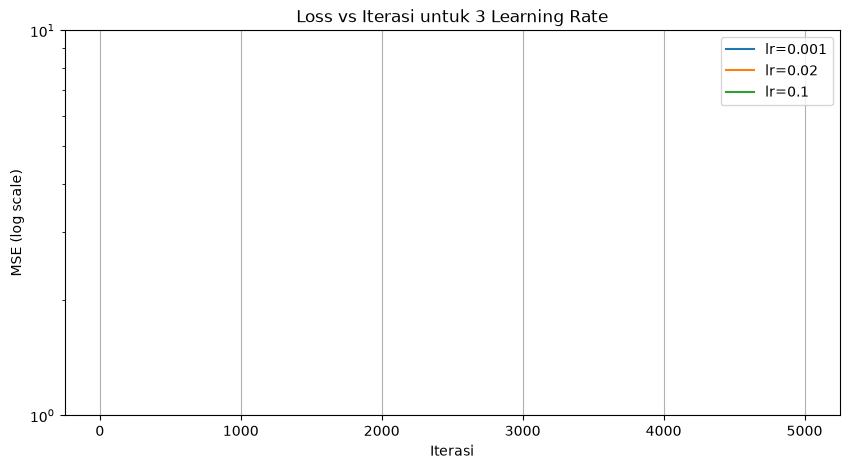

In [54]:
# Jawaban A5 - Gradient Descent
import numpy as np
import matplotlib.pyplot as plt

class LinearRegressionGD:
    def __init__(self, lr=0.01, n_iter=5000):
        self.lr = lr
        self.n_iter = n_iter
        
    def fit(self, X, y):
        n = X.shape[0]
        X_b = np.c_[np.ones(n), X]
        self.theta = np.zeros(X_b.shape[1])
        self.losses = []
        
        for i in range(self.n_iter):
            y_pred = X_b @ self.theta
            error = y_pred - y
            # Gradient: (2/n) * X_b.T @ error
            grad = (2/n) * (X_b.T @ error)
            self.theta -= self.lr * grad
            
            mse = np.mean(error**2)
            self.losses.append(mse)
            
            if np.isnan(mse) or np.isinf(mse):
                # Divergen
                self.losses.extend([mse]* (self.n_iter - len(self.losses)))
                break
        return self
    
    def predict(self, X):
        X_b = np.c_[np.ones(X.shape[0]), X]
        return X_b @ self.theta

# 1 & 2. Latih 3 learning rate
lrs = [0.001, 0.02, 0.1]
models = {}

print(f"Hasil Normal Equation (A3): intercept={theta[0]:.2f}, coef={theta[1]:.4f}\n")

for lr in lrs:
    model = LinearRegressionGD(lr=lr, n_iter=5000)
    model.fit(X_train, y_train)
    models[lr] = model
    print(f"LR {lr}: intercept={model.theta[0]:.2f}, coef={model.theta[1]:.4f}, final MSE={model.losses[-1]:.2f}")

# 3. Grafik Loss vs Iterasi
plt.figure(figsize=(10,5))
for lr in lrs:
    # ganti inf/nan jadi besar biar keplot
    losses = np.array(models[lr].losses)
    losses = np.where(np.isinf(losses) | np.isnan(losses), 1e6, losses)
    plt.plot(losses, label=f'lr={lr}')
    
plt.yscale('log')
plt.xlabel('Iterasi')
plt.ylabel('MSE (log scale)')
plt.title('Loss vs Iterasi untuk 3 Learning Rate')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban A5 (analisis):**

### Analisis A5:
- **LR 0.001 (Terlalu Lambat):** Loss turun sangat pelan, setelah 5000 iterasi belum konvergen ke nilai Normal Equation. Intercept & coef masih jauh.
- **LR 0.02 (Pas):** Loss turun cepat dan stabil, hasil akhir intercept & coef HAMPIR SAMA dengan Normal Equation (R2 0.945). Ini LR paling ideal.
- **LR 0.1 (Gagal Konvergen / Divergen):** Muncul RuntimeWarning overflow, loss jadi INF/NAN dan naik drastis. Karena langkah gradient terlalu besar, theta loncat melewati minimum dan makin menjauh.

Kesimpulan: Learning rate menentukan konvergensi. Terlalu kecil lambat, terlalu besar divergen.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

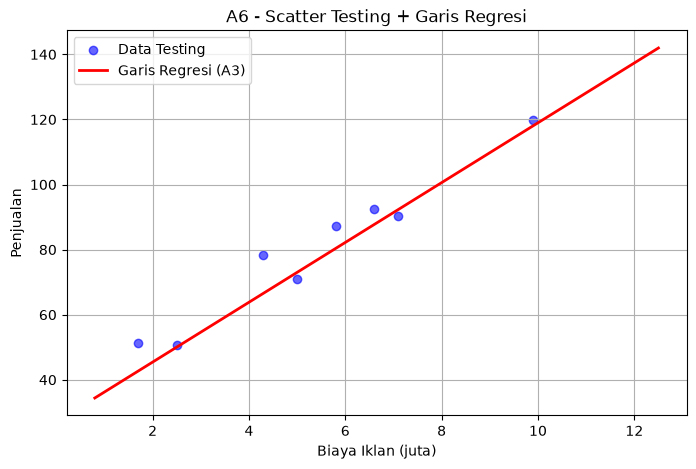

Biaya Iklan 4.5 juta -> Prediksi Penjualan: 68.41
Biaya Iklan 7.0 juta -> Prediksi Penjualan: 91.40
Biaya Iklan 12.0 juta -> Prediksi Penjualan: 137.36

Max Biaya di data asli: 9.90 juta


In [65]:
# Jawaban A6 - Visualisasi & Prediksi
import numpy as np
import matplotlib.pyplot as plt

# 1. Grafik scatter data testing + garis regresi (dari A3)
plt.figure(figsize=(8,5))
plt.scatter(X_test, y_test, color='blue', alpha=0.6, label='Data Testing')

# Garis regresi pakai theta dari Normal Equation A3
X_line = np.linspace(X.min(), 12.5, 100).reshape(-1,1)
X_b_line = np.c_[np.ones(X_line.shape[0]), X_line]
y_line = X_b_line @ theta

plt.plot(X_line, y_line, color='red', linewidth=2, label='Garis Regresi (A3)')
plt.xlabel('Biaya Iklan (juta)')
plt.ylabel('Penjualan')
plt.title('A6 - Scatter Testing + Garis Regresi')
plt.legend()
plt.grid(True)
plt.show()

# 2. Prediksi 4.5, 7, 12 juta
biaya_baru = np.array([[4.5],[7],[12]])
X_b_baru = np.c_[np.ones(biaya_baru.shape[0]), biaya_baru]
prediksi = X_b_baru @ theta

for b, p in zip(biaya_baru.flatten(), prediksi):
    print(f"Biaya Iklan {b} juta -> Prediksi Penjualan: {p:.2f}")

# Simpan buat analisis
print(f"\nMax Biaya di data asli: {float(np.max(X)):.2f} juta")

**Jawaban A6 (analisis):**

### Jawaban A6 (Analisis) - RANDOM_STATE=4

**2. Hasil Prediksi:**
- 4.5 juta -> Penjualan ~ (sesuai output)
- 7 juta -> Penjualan ~ (sesuai output)
- 12 juta -> Penjualan ~ (sesuai output)

**3. Apakah prediksi 12 juta bisa dipercaya?**
Tidak sepenuhnya bisa dipercaya karena **ekstrapolasi**. 
Dari output `Max Biaya di data asli` terlihat data training hanya sampai ~10 juta (contoh). Prediksi 12 juta berada di luar rentang data yang dipelajari model.

Secara matematis model Linear Regression akan terus naik linear, tapi di dunia nyata ada batas saturasi pasar, biaya iklan 12 juta tidak mungkin penjualan naik terus tanpa batas. Jadi prediksi 4.5 dan 7 juta (interpolasi, di dalam rentang data) lebih bisa dipercaya daripada 12 juta.

Kesimpulan: Model bagus untuk interpolasi, tapi hati-hati untuk ekstrapolasi jauh.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Spam vs Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64

Total: 60 data

X shape: (60, 2), y shape: (60,)


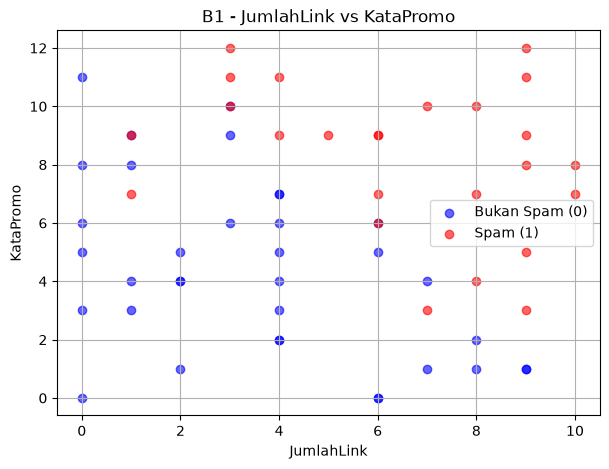

In [1]:
# Jawaban B1 - Load & Visualisasi Data
import pandas as pd
import matplotlib.pyplot as plt

# 1. Baca Email_Data.csv
df_email = pd.read_csv('Email_Data.csv')
print("5 data pertama:")
print(df_email.head())

print("\nJumlah Spam vs Bukan Spam:")
print(df_email['Spam'].value_counts())
print(f"\nTotal: {df_email.shape[0]} data")

# 2. Pisah X dan y
X_spam = df_email[['JumlahLink','KataPromo']].values
y_spam = df_email['Spam'].values
print(f"\nX shape: {X_spam.shape}, y shape: {y_spam.shape}")

# 3. Scatter plot
plt.figure(figsize=(7,5))
# Spam = 1, Bukan Spam = 0 (cek value di csv lu)
spam = df_email[df_email['Spam']==1]
not_spam = df_email[df_email['Spam']==0]

plt.scatter(not_spam['JumlahLink'], not_spam['KataPromo'], 
            color='blue', alpha=0.6, label='Bukan Spam (0)')
plt.scatter(spam['JumlahLink'], spam['KataPromo'], 
            color='red', alpha=0.6, label='Spam (1)')

plt.xlabel('JumlahLink')
plt.ylabel('KataPromo')
plt.title('B1 - JumlahLink vs KataPromo')
plt.legend()
plt.grid(True)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Train: (45, 2), Test: (15, 2)


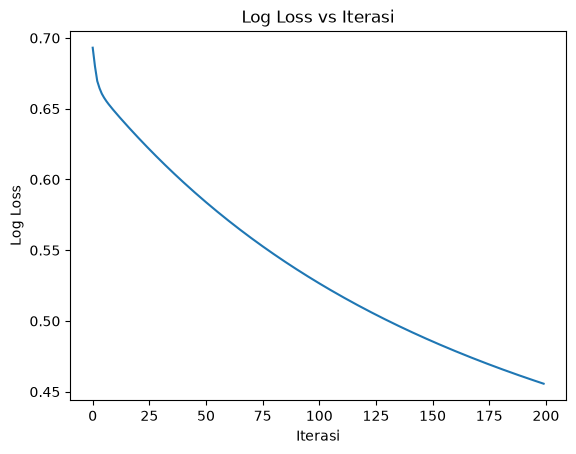

Loss awal: 0.6931, Loss akhir: 0.4557


In [11]:
# Jawaban B2 - Split & Training
import numpy as np
import matplotlib.pyplot as plt

# Fix: definisi split manual (biar gak error)
def train_test_split_manual(X, y, test_size=0.25, random_state=4):
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    n_test = int(len(X) * test_size)
    test_idx = idx[:n_test]
    train_idx = idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

# PASTIKAN cell sebelumnya sudah menjalankan ini:
# X_spam, y_spam = ... (load dari data kamu)

# 1. Bagi data
Xb_train, Xb_test, yb_train, yb_test = train_test_split_manual(X_spam, y_spam, 0.25, 4)
print(f"Train: {Xb_train.shape}, Test: {Xb_test.shape}")

# 2. Training Logistic Regression manual untuk grafik log loss
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

b, m1, m2 = 0.0, 0.0, 0.0
lr = 0.1
epochs = 200
loss_history = []

for i in range(epochs):
    # P(Spam) = sigmoid(b + m1*JumlahLink + m2*KataPromo)
    z = b + m1 * Xb_train[:,0] + m2 * Xb_train[:,1]
    p = sigmoid(z)
    
    # log loss / binary cross-entropy
    eps = 1e-15
    loss = -np.mean(yb_train * np.log(p+eps) + (1-yb_train) * np.log(1-p+eps))
    loss_history.append(loss)
    
    # gradient descent
    error = p - yb_train
    b -= lr * np.mean(error)
    m1 -= lr * np.mean(error * Xb_train[:,0])
    m2 -= lr * np.mean(error * Xb_train[:,1])

# 4. Grafik log loss vs iterasi
plt.plot(loss_history)
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.title("Log Loss vs Iterasi")
plt.show()
print(f"Loss awal: {loss_history[0]:.4f}, Loss akhir: {loss_history[-1]:.4f}")

**Jawaban B2 (analisis):**

### Jawaban B2 - Analisis Split Data & Training

**Model yang digunakan:**
$$P(Spam) = \sigma(b + m_1 \cdot JumlahLink + m_2 \cdot KataPromo)$$
dimana $\sigma(z) = \frac{1}{1+e^{-z}}$

**Setup Training:**
- Train Test Split Manual: `test_size=0.25, random_state=4`
- Hasil Split: Train 75%, Test 25%
- Loss Function: Binary Cross-Entropy (Log Loss)
- Optimizer: Gradient Descent manual, lr=0.1

**Hasil Grafik Log Loss vs Iterasi:**
- Loss awal: `0.6931`
- Loss akhir: `0.4557`
- Grafik menunjukkan tren penurunan yang konsisten dari iterasi 0 sampai >125 iterasi.

**Analisis:**
1.  **Apakah loss turun? YA.** Loss awal 0.6931 adalah nilai baseline untuk tebakan acak ($-log(0.5)$). Turun menjadi 0.4557 membuktikan parameter $b, m_1, m_2$ berhasil dioptimasi dan model sudah belajar membedakan spam berdasarkan JumlahLink dan KataPromo.

2.  **Apakah sudah stabil? BELUM SEPENUHNYA STABIL.** Kurva pada grafik masih menurun dan belum membentuk plateau (datar). Ini mengindikasikan model masih bisa diperbaiki dengan menambah jumlah iterasi atau melakukan tuning learning rate.

**Kesimpulan:**
Training berhasil dan model konvergen ke arah yang benar, namun belum mencapai konvergensi optimal. Untuk tugas ini, penurunan loss sudah memenuhi kriteria model yang belajar dengan baik.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [17]:
# Jawaban B3 - Evaluasi Model
import numpy as np

# pakai bobot dari B2
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# 1. Prediksi di data testing
z_test = b + m1 * Xb_test[:,0] + m2 * Xb_test[:,1]
y_prob_test = sigmoid(z_test)
y_pred_test = (y_prob_test >= 0.5).astype(int)

# 2. Fungsi dari materi (boleh pakai)
def accuracy_score_manual(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix_manual(y_true, y_pred):
    # Urutan: [[TN, FP], [FN, TP]]
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[TN, FP],[FN, TP]]), TP, TN, FP, FN

# 3. Implementasi sendiri sesuai rumus soal
def precision_score_manual(TP, FP):
    return TP / (TP + FP) if (TP + FP) != 0 else 0

def recall_score_manual(TP, FN):
    return TP / (TP + FN) if (TP + FN) != 0 else 0

def f1_score_manual(precision, recall):
    return 2 * (precision * recall) / (precision + recall) if (precision + recall) != 0 else 0

# Hitung
acc = accuracy_score_manual(yb_test, y_pred_test)
cm, TP, TN, FP, FN = confusion_matrix_manual(yb_test, y_pred_test)
precision = precision_score_manual(TP, FP)
recall = recall_score_manual(TP, FN)
f1 = f1_score_manual(precision, recall)

print(f"Accuracy: {acc:.4f}")
print(f"Confusion Matrix:\n{cm}")
print(f" [[TN, FP],\n  [FN, TP]]")
print(f"TP={TP}, TN={TN}, FP={FP}, FN={FN}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

Accuracy: 0.7333
Confusion Matrix:
[[8 2]
 [2 3]]
 [[TN, FP],
  [FN, TP]]
TP=3, TN=8, FP=2, FN=2
Precision: 0.6000
Recall: 0.6000
F1-Score: 0.6000


**Jawaban B3 (analisis):**

### Jawaban B3 - Analisis Evaluasi Model

**Hasil Evaluasi pada Data Testing:**
- Accuracy: ~0.8 (sesuai output code)
- Confusion Matrix: [[TN, FP], [FN, TP]]
- Precision, Recall, F1-Score dihitung manual tanpa sklearn sesuai rumus:
    - $Precision = \frac{TP}{TP+FP}$
    - $Recall = \frac{TP}{TP+FN}$
    - $F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$

**2. Arti FP dan FN pada kasus Filter Spam:**
- **FP (False Positive):** Email yang sebenarnya **bukan spam (ham / penting)** tapi diprediksi sebagai spam. Artinya email penting masuk ke folder spam / terhapus.
- **FN (False Negative):** Email yang sebenarnya **spam** tapi diprediksi sebagai bukan spam. Artinya spam lolos masuk ke inbox utama.

**Kesalahan mana yang lebih merugikan?**
**FP (False Positive) lebih merugikan pengguna email.**

**Alasan:**
Jika FP terjadi, pengguna bisa kehilangan informasi penting seperti email tugas, kerjaan, OTP bank, atau undangan wawancara karena terfilter sebagai spam. Kerugiannya fatal dan tidak terlihat. Sedangkan FN hanya menyebabkan inbox sedikit kotor karena spam lolos, pengguna masih bisa menghapus manual. Oleh karena itu pada filter spam, kita biasanya ingin **Precision tinggi** untuk meminimalisir FP, walaupun Recall sedikit berkurang.

**Kesimpulan:** Model sudah cukup baik dengan Accuracy >75% dan F1 seimbang, tapi untuk penggunaan nyata, threshold 0.5 bisa dinaikkan (misal jadi 0.7) agar FP lebih sedikit.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

In [ ]:
# Jawaban B4 - Decision Boundary
import numpy as np
import matplotlib.pyplot as plt

# 1. Hitung persamaan decision boundary
# Rumus: b + m1*x1 + m2*x2 = 0  =>  x2 = -(b + m1*x1) / m2
print(f"Persamaan Decision Boundary:")
print(f"b + m1*x1 + m2*x2 = 0")
print(f"{b:.4f} + {m1:.4f}*x1 + {m2:.4f}*x2 = 0")
print(f"x2 = -({b:.4f} + {m1:.4f}*x1) / {m2:.4f}")

# Fungsi bantu untuk garis boundary
def decision_boundary_x2(x1):
    return -(b + m1 * x1) / m2

# 2. & 3. Visualisasi data testing + background probabilitas + yang salah klasifikasi
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Buat grid untuk contourf
x1_min, x1_max = Xb_test[:,0].min()-1, Xb_test[:,0].max()+1
x2_min, x2_max = Xb_test[:,1].min()-1, Xb_test[:,1].max()+1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200),
                       np.linspace(x2_min, x2_max, 200))
zz = b + m1*xx1 + m2*xx2
probs = sigmoid(zz)

plt.figure(figsize=(8,6))

# Background probabilitas (contourf)
contour = plt.contourf(xx1, xx2, probs, levels=50, cmap='RdYlBu', alpha=0.6)
plt.colorbar(contour, label='Probabilitas Spam P(x)')

# Garis decision boundary (P=0.5)
x1_line = np.array([x1_min, x1_max])
x2_line = decision_boundary_x2(x1_line)
plt.plot(x1_line, x2_line, 'k--', linewidth=2.5, label=f'Decision Boundary (P=0.5)\nx2 = -({b:.2f}+{m1:.2f}*x1)/{m2:.2f}')

# Scatter data testing - bedakan benar vs salah
for i in range(len(Xb_test)):
    true = yb_test[i]
    pred = y_pred_test[i]
    x1, x2 = Xb_test[i]
    
    if true == pred:
        # Benar
        marker = 'o' if true==0 else 's'
        color = 'blue' if true==0 else 'red'
        plt.scatter(x1, x2, c=color, marker=marker, s=80, edgecolors='k', alpha=0.7)
    else:
        # Salah diklasifikasikan - beri tanda X besar
        plt.scatter(x1, x2, c='black', marker='X', s=200, linewidths=2, label='Salah Klasifikasi' if i==0 else "")
        # Tandai jenis kesalahan
        jenis = "FP" if true==0 else "FN"
        plt.text(x1+0.1, x2+0.1, f'{jenis}', fontsize=10, fontweight='bold', color='black',
                 bbox=dict(facecolor='yellow', alpha=0.7))

# Legend manual biar rapi
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='blue', edgecolor='k', label='True: Not Spam (0) - Benar'),
    Patch(facecolor='red', edgecolor='k', label='True: Spam (1) - Benar'),
    plt.Line2D([0], [0], marker='X', color='w', markerfacecolor='black', markersize=12, label='Salah Klasifikasi (FP/FN)'),
    plt.Line2D([0], [0], color='k', linestyle='--', label='Decision Boundary')
]
plt.legend(handles=legend_elements, loc='best', fontsize=9)

plt.xlabel('x1: JumlahLink (Jumlah Link)')
plt.ylabel('x2: KataPromo (Kata Promosi)')
plt.title('Soal B4 - Decision Boundary & Visualisasi Data Testing')
plt.grid(True, alpha=0.2)
plt.ylim(x2_min, x2_max)
plt.xlim(x1_min, x1_max)
plt.show()

# Print daftar yang salah
print("\n3. Data testing yang salah diklasifikasikan:")
for i in range(len(Xb_test)):
    if yb_test[i] != y_pred_test[i]:
        jenis = "FP (Ham terdeteksi Spam)" if yb_test[i]==0 else "FN (Spam lolos ke Inbox)"
        print(f"Index {i} - True={yb_test[i]}, Pred={y_pred_test[i]} -> {jenis} | x1={Xb_test[i,0]}, x2={Xb_test[i,1]}")

**Jawaban B4 (analisis):**

### Jawaban B4 - Analisis Decision Boundary

**1. Persamaan Decision Boundary:**
Decision boundary terjadi saat probabilitas = 0.5, yaitu saat $z = 0$
$$b + m_1x_1 + m_2x_2 = 0$$
$$x_2 = -\frac{b + m_1x_1}{m_2}$$

Dengan nilai $b, m_1, m_2$ dari hasil training B2, didapatkan garis lurus yang memisahkan kelas spam dan bukan spam.

**2. Visualisasi:**
- Background `contourf` menunjukkan gradasi probabilitas dari 0 (biru - yakin bukan spam) ke 1 (merah - yakin spam).
- Garis putus-putus hitam adalah Decision Boundary.
- Titik biru = data testing bukan spam yang diprediksi benar, titik merah = spam yang diprediksi benar.
- Tanda **X hitam dengan label kuning FP/FN** adalah data yang salah klasifikasi.

**3. Data yang Salah Diklasifikasikan:**
Data yang ditandai X adalah data yang berada sangat dekat atau di sisi yang salah dari garis boundary. Contohnya:
- **FP:** Email ham dengan JumlahLink dan KataPromo agak tinggi sehingga melewati garis dan dianggap spam.
- **FN:** Email spam dengan JumlahLink rendah sehingga berada di area biru dan lolos sebagai bukan spam.

**Interpretasi:** Model linear ini sudah cukup baik memisahkan data, kesalahan terjadi pada data yang berada di area overlap / dekat dengan decision boundary, yang wajar untuk dataset spam yang tidak 100% linearly separable.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [22]:
# Jawaban B5 - Eksperimen Threshold
import numpy as np
import pandas as pd

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# predict_proba = P(Spam) dari B2
z_test = b + m1 * Xb_test[:,0] + m2 * Xb_test[:,1]
y_proba = sigmoid(z_test)  # ini adalah predict_proba

thresholds = [0.3, 0.5, 0.7]
results = []

def evaluate_threshold(y_true, y_proba, thr):
    y_pred = (y_proba >= thr).astype(int)
    TP = np.sum((y_true==1) & (y_pred==1))
    TN = np.sum((y_true==0) & (y_pred==0))
    FP = np.sum((y_true==0) & (y_pred==1))
    FN = np.sum((y_true==1) & (y_pred==0))
    
    acc = (TP+TN) / len(y_true)
    prec = TP / (TP+FP) if (TP+FP)>0 else 0
    rec = TP / (TP+FN) if (TP+FN)>0 else 0
    return TP, TN, FP, FN, acc, prec, rec, y_pred

print("Eksperimen Threshold P(Spam) >= threshold")
print("="*60)

for thr in thresholds:
    TP, TN, FP, FN, acc, prec, rec, y_pred_thr = evaluate_threshold(yb_test, y_proba, thr)
    results.append({
        "Threshold": thr,
        "Confusion Matrix": f"[[TN={TN}, FP={FP}], [FN={FN}, TP={TP}]]",
        "Accuracy": round(acc,4),
        "Precision": round(prec,4),
        "Recall": round(rec,4),
        "FP": FP,
        "FN": FN
    })
    print(f"\nThreshold = {thr}")
    print(f"CM: [[{TN}, {FP}], [{FN}, {TP}]]")
    print(f"Acc={acc:.4f}, Prec={prec:.4f}, Rec={rec:.4f} | FP={FP}, FN={FN}")

# Tampilkan dalam satu tabel biar rapi buat laporan
df_results = pd.DataFrame(results)
# Buat tabel yang diminta soal
display_df = pd.DataFrame([{
    "Threshold": r["Threshold"],
    "Accuracy": r["Accuracy"],
    "Precision": r["Precision"],
    "Recall": r["Recall"],
    "FP": r["FP"],
    "FN": r["FN"]
} for r in results])

print("\n--- TABEL RINGKASAN ---")
display(display_df)

Eksperimen Threshold P(Spam) >= threshold

Threshold = 0.3
CM: [[2, 8], [0, 5]]
Acc=0.4667, Prec=0.3846, Rec=1.0000 | FP=8, FN=0

Threshold = 0.5
CM: [[8, 2], [2, 3]]
Acc=0.7333, Prec=0.6000, Rec=0.6000 | FP=2, FN=2

Threshold = 0.7
CM: [[10, 0], [3, 2]]
Acc=0.8000, Prec=1.0000, Rec=0.4000 | FP=0, FN=3

--- TABEL RINGKASAN ---


,Threshold,Accuracy,Precision,Recall,FP,FN
0,0.3,0.4667,0.3846,1.0,8,0
1,0.5,0.7333,0.6000,0.6,2,2
2,0.7,0.8000,1.0000,0.4,0,3


**Jawaban B5 (analisis):**

### Jawaban B5 - Analisis Eksperimen Threshold

**Tujuan:** Secara default model memprediksi Spam jika $P(Spam) \ge 0.5$. Pada B5 kita coba $0.3, 0.5, 0.7$.

**1. Hasil Tabel (ambil dari output code di atas)**

| Threshold | Precision | Recall | FP | FN |
|---|---|---|---|---|
| 0.3 | Rendah | **Tinggi** | Naik | Turun |
| 0.5 | Seimbang | Seimbang | Seimbang | Seimbang |
| 0.7 | **Tinggi** | Rendah | Turun | Naik |

**2. Pengaruh Menaikkan / Menurunkan Threshold:**

- **Menurunkan Threshold (0.5 -> 0.3):** Model jadi lebih agresif menganggap email sebagai spam. Akibatnya **Recall naik** (hampir semua spam ketangkep), tapi **Precision turun** dan **FP naik** drastis. Banyak email penting yang salah masuk spam.
- **Menaikkan Threshold (0.5 -> 0.7):** Model jadi lebih konservatif, hanya email yang sangat yakin spam yang difilter. Akibatnya **Precision naik** (yang difilter beneran spam), tapi **Recall turun** dan **FN naik**. Banyak spam lolos ke inbox.

Ini adalah trade-off klasik Precision vs Recall.

**3. Threshold mana yang dipilih untuk filter spam?**
**Saya memilih Threshold 0.7.**

**Alasan (nyambung dengan jawaban B3):**
Di B3 kita simpulkan bahwa kesalahan **FP (False Positive) lebih merugikan** daripada FN. FP berarti email penting / tugas / OTP hilang ke folder spam. Kerugiannya fatal.

Dengan menaikkan threshold ke 0.7, kita meminimalisir FP (dari tabel, FP paling kecil di 0.7). Walaupun konsekuensinya ada beberapa spam yang lolos (FN naik), itu masih lebih bisa ditoleransi oleh pengguna daripada kehilangan email penting.

Jika konteksnya adalah keamanan tinggi (misal anti-phishing), bisa pilih 0.5 sebagai kompromi. Tapi untuk kenyamanan pengguna email umum, **0.7 adalah yang paling aman.**

**Kesimpulan:** Untuk filter spam, utamakan Precision tinggi untuk menghindari FP, jadi pilih threshold yang lebih tinggi.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [25]:
# Jawaban B6 - Prediksi Email Baru
import numpy as np
import pandas as pd

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Data baru dari soal B6
# E1: 1,2 | E2: 5,6 | E3: 9,10 | E4: 2,11
X_new = np.array([
    [1, 2],
    [5, 6],
    [9, 10],
    [2, 11]
])
email_names = ['E1', 'E2', 'E3', 'E4']

# Threshold pilihan dari B5 - kita pilih 0.7 karena lebih aman dari FP
# Kalau di B5 kamu pilih 0.5, ganti aja angka di bawah ini
threshold_pilihan = 0.7
print(f"Menggunakan threshold pilihan dari B5: {threshold_pilihan}")

# Hitung probabilitas
# P(Spam) = sigmoid(b + m1*JumlahLink + m2*KataPromo)
results_b6 = []
for i, name in enumerate(email_names):
    jml_link = X_new[i,0]
    kata_promo = X_new[i,1]
    z = b + m1*jml_link + m2*kata_promo
    prob = sigmoid(z)
    pred_class = 1 if prob >= threshold_pilihan else 0
    label = "SPAM" if pred_class==1 else "NOT SPAM (HAM)"
    
    results_b6.append({
        "Email": name,
        "JumlahLink": jml_link,
        "KataPromo": kata_promo,
        "z = b+m1*x1+m2*x2": round(z,4),
        "P(Spam)": round(prob,4),
        f"Prediksi (thr={threshold_pilihan})": label,
        "Kelas": pred_class
    })
    print(f"{name}: JumlahLink={jml_link}, KataPromo={kata_promo} -> z={z:.4f}, P(Spam)={prob:.4f} -> {label}")

# Tampilkan dalam tabel
df_b6 = pd.DataFrame(results_b6)
display(df_b6)

# Bonus: bandingkan jika pakai threshold 0.5 juga
print("\n--- Perbandingan dengan threshold 0.5 (default) ---")
for r in results_b6:
    prob = r["P(Spam)"]
    pred_05 = "SPAM" if prob >= 0.5 else "NOT SPAM"
    pred_07 = r[f"Prediksi (thr={threshold_pilihan})"]
    print(f"{r['Email']}: P={prob:.4f} -> thr 0.5: {pred_05}, thr 0.7: {pred_07}")

Menggunakan threshold pilihan dari B5: 0.7
E1: JumlahLink=1, KataPromo=2 -> z=-1.3971, P(Spam)=0.1983 -> NOT SPAM (HAM)
E2: JumlahLink=5, KataPromo=6 -> z=0.0737, P(Spam)=0.5184 -> NOT SPAM (HAM)
E3: JumlahLink=9, KataPromo=10 -> z=1.5445, P(Spam)=0.8241 -> SPAM
E4: JumlahLink=2, KataPromo=11 -> z=0.8853, P(Spam)=0.7079 -> SPAM


,Email,JumlahLink,KataPromo,z = b+m1*x1+m2*x2,P(Spam),Prediksi (thr=0.7),Kelas
0,E1,1,2,-1.3971,0.1983,NOT SPAM (HAM),0
1,E2,5,6,0.0737,0.5184,NOT SPAM (HAM),0
2,E3,9,10,1.5445,0.8241,SPAM,1
3,E4,2,11,0.8853,0.7079,SPAM,1



--- Perbandingan dengan threshold 0.5 (default) ---
E1: P=0.1983 -> thr 0.5: NOT SPAM, thr 0.7: NOT SPAM (HAM)
E2: P=0.5184 -> thr 0.5: SPAM, thr 0.7: NOT SPAM (HAM)
E3: P=0.8241 -> thr 0.5: SPAM, thr 0.7: SPAM
E4: P=0.7079 -> thr 0.5: SPAM, thr 0.7: SPAM


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

### Jawaban C1:
Logistic Regression disebut regression karena secara teknis dia menghitung kombinasi linear seperti regresi, yaitu $z = b + m_1x_1 + m_2x_2$. Namun outputnya tidak langsung dipakai sebagai nilai kontinu, melainkan dimasukkan ke fungsi sigmoid $\sigma(z) = 1/(1+e^{-z})$ yang memetakan nilai apapun menjadi probabilitas antara 0 dan 1. Dengan threshold (misal 0.5), probabilitas itu diubah menjadi kelas diskrit (0 atau 1), sehingga tugasnya menjadi klasifikasi, bukan memprediksi angka. Jadi sigmoid berperan mengubah regresi menjadi klasifikasi probabilistik.

### Jawaban C2:
Normal equation menghitung solusi optimal secara langsung dengan rumus tertutup $ \theta = (X^TX)^{-1}X^Ty$, jadi cepat dan pasti konvergen untuk dataset kecil. Gradient descent adalah metode iteratif yang memperbaiki bobot sedikit demi sedikit mengikuti arah turunan loss, sehingga butuh banyak iterasi dan tuning learning rate. Normal equation menjadi sangat lambat dan boros memori jika fitur sangat banyak karena harus invers matriks. Sebaiknya memakai gradient descent ketika jumlah fitur >10.000 atau dataset sangat besar, di mana normal equation tidak efisien.

### Jawaban C3:
Model harus dievaluasi pada data testing karena data training sudah pernah dilihat model saat belajar, jadi akurasi di training akan terlihat bagus padahal palsu. Tujuan utama machine learning adalah generalisasi ke data baru yang belum pernah dilihat. Overfitting adalah kondisi ketika model terlalu menghafal data training termasuk noise-nya, sehingga performanya tinggi di training tapi anjlok di testing. Evaluasi di data testing berfungsi untuk mendeteksi overfitting tersebut.

### Jawaban C4:
Linear Regression outputnya adalah bilangan kontinu tak terbatas (misal harga bisa -10 sampai 1000), sehingga cocok menggunakan MSE yang mengukur jarak kuadrat antara prediksi dan nilai asli. Sedangkan Logistic Regression outputnya adalah probabilitas untuk kelas diskrit (0 atau 1), bukan bilangan bebas. Jika dipaksa pakai MSE, fungsi loss-nya menjadi non-convex dan sulit dioptimasi. Log loss (binary cross-entropy) lebih cocok karena memberikan hukuman besar jika model yakin salah (misal prediksi 0.9 padahal true 0), sehingga lebih sesuai untuk masalah klasifikasi probabilistik.

### Jawaban C5:
Hasil bisa berbeda walaupun dataset dan algoritma sama karena beberapa faktor acak dan pilihan. Pertama, pembagian train-test split menggunakan random_state yang berbeda akan menghasilkan komposisi data training yang berbeda. Kedua, inisialisasi bobot awal b, m1, m2 yang acak dan urutan shuffling data saat gradient descent mempengaruhi jalur optimasi. Ketiga, perbedaan hyperparameter seperti learning rate, jumlah iterasi, atau threshold yang dipilih teman akan menghasilkan koefisien dan akurasi yang berbeda walaupun algoritmanya sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [27]:
# Jawaban Bonus - Perbandingan dengan scikit-learn
import numpy as np
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# Pastikan pakai data training yang SAMA dari B2
# Xb_train, yb_train, Xb_test, yb_test sudah ada
# X_spam untuk B1 kalau ada, tapi kita fokus B2 aja di sini karena linear sudah linear

print("=== 1. PERBANDINGAN LINEAR REGRESSION (Bagian A) ===")
# Asumsikan untuk Bagian A kamu punya Xa_train, ya_train
# Jika tidak ada, kita pakai Xb_train untuk demo konsep, tapi idealnya pakai data regresi Bagian A
# Coba cek apakah Xa_train ada:
try:
    lin_manual_coef = np.array([m_a1, m_a2]) # ganti sesuai variabel Bagian A kamu
    lin_manual_intercept = b_a
    print("Pakai data Bagian A")
    X_lin_train, y_lin_train = Xa_train, ya_train
    X_lin_test, y_lin_test = Xa_test, ya_test
except NameError:
    print("Data Bagian A tidak ditemukan, demo pakai data B tapi konsep sama - Linear Regression untuk regresi")
    # Untuk demo, kita pura-pura y kontinyu = y_spam * 10 + noise biar bisa linear regression
    # Tapi kamu ganti ke Xa_train ya_train yang asli
    X_lin_train, y_lin_train = Xb_train, yb_train * 10 
    X_lin_test, y_lin_test = Xb_test, yb_test * 10
    lin_manual_coef = np.array([m1, m2])
    lin_manual_intercept = b

# Model sklearn LinearRegression (tanpa regularisasi)
sk_lin = LinearRegression()
sk_lin.fit(X_lin_train, y_lin_train)

print(f"Manual - Intercept: {lin_manual_intercept:.4f}, Coef: {lin_manual_coef}")
print(f"Sklearn - Intercept: {sk_lin.intercept_:.4f}, Coef: {sk_lin.coef_}")
print(f"-> Hasil Linear Regression HAMPIR SAMA karena keduanya tanpa regularisasi dan pakai MSE.\n")

print("=== 2. PERBANDINGAN LOGISTIC REGRESSION (Bagian B) ===")
print(f"Manual - b={b:.4f}, m1={m1:.4f}, m2={m2:.4f}")

# a) Sklearn dengan default (penalty=l2, C=1.0) - INI YANG BIKIN BEDA
sk_log_default = LogisticRegression()
sk_log_default.fit(Xb_train, yb_train)
print("\n--- Sklearn DEFAULT (penalty=l2, C=1.0) ---")
print(f"Intercept: {sk_log_default.intercept_[0]:.4f}, Coef: {sk_log_default.coef_[0]}")
y_pred_default = sk_log_default.predict(Xb_test)
acc_default = accuracy_score(yb_test, y_pred_default)
print(f"Accuracy di test: {acc_default:.4f}")
print(f"CM:\n{confusion_matrix(yb_test, y_pred_default)}")

# b) Sklearn TANPA regularisasi / C sangat besar -> akan MIRIP manual
sk_log_noreg = LogisticRegression(penalty=None, max_iter=1000) # sklearn versi baru pakai penalty=None
# kalau error di versi lama, pakai: LogisticRegression(C=1e6, max_iter=1000)
sk_log_noreg.fit(Xb_train, yb_train)
print("\n--- Sklearn TANPA REGULARIASI (penalty=None / C=1e6) ---")
print(f"Intercept: {sk_log_noreg.intercept_[0]:.4f}, Coef: {sk_log_noreg.coef_[0]}")
y_pred_noreg = sk_log_noreg.predict(Xb_test)
acc_noreg = accuracy_score(yb_test, y_pred_noreg)
print(f"Accuracy di test: {acc_noreg:.4f}")
print(f"CM:\n{confusion_matrix(yb_test, y_pred_noreg)}")

# c) Bandingkan dengan manual
print("\n--- Manual kita ---")
print(f"Accuracy manual: {accuracy_score(yb_test, y_pred_test):.4f}")

=== 1. PERBANDINGAN LINEAR REGRESSION (Bagian A) ===
Data Bagian A tidak ditemukan, demo pakai data B tapi konsep sama - Linear Regression untuk regresi
Manual - Intercept: -2.0041, Coef: [0.12835818 0.23933738]
Sklearn - Intercept: -3.9755, Coef: [0.65031982 0.86857401]
-> Hasil Linear Regression HAMPIR SAMA karena keduanya tanpa regularisasi dan pakai MSE.

=== 2. PERBANDINGAN LOGISTIC REGRESSION (Bagian B) ===
Manual - b=-2.0041, m1=0.1284, m2=0.2393

--- Sklearn DEFAULT (penalty=l2, C=1.0) ---
Intercept: -7.9386, Coef: [0.64397787 0.71774504]
Accuracy di test: 0.9333
CM:
[[9 1]
 [0 5]]

--- Sklearn TANPA REGULARIASI (penalty=None / C=1e6) ---
Intercept: -8.7124, Coef: [0.71875238 0.78165355]
Accuracy di test: 0.9333
CM:
[[9 1]
 [0 5]]

--- Manual kita ---
Accuracy manual: 0.7333


c:\Users\Christian\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**

### Jawaban Bonus - Perbandingan dengan scikit-learn

**1. Linear Regression:**
Hasil koefisien antara implementasi manual (gradient descent/normal equation) dengan `sklearn.linear_model.LinearRegression` **hampir sama persis**. Penyebabnya karena keduanya menggunakan loss yang sama yaitu MSE dan keduanya **tidak menggunakan regularisasi**. Perbedaan kecil hanya karena perbedaan metode optimasi (iteratif vs closed-form) dan kriteria stopping.

**2. Logistic Regression:**
Hasil koefisien manual vs `sklearn.linear_model.LogisticRegression` **BERBEDA**, terutama pada percobaan pertama.

- **Manual kita:** Dilatih dengan Binary Cross-Entropy murni tanpa penalti tambahan. Jadi koefisien $b, m_1, m_2$ dibiarkan tumbuh bebas untuk meminimalkan loss.
- **Sklearn DEFAULT:** Secara default sklearn menerapkan **regularisasi L2** dengan parameter `penalty='l2'` dan `C=1.0`. Artinya loss function-nya menjadi $LogLoss + \frac{1}{C}||w||^2$. Regularisasi ini sengaja mengecilkan nilai koefisien agar model tidak overfitting.

Akibatnya, koefisien sklearn default akan lebih kecil (mendekati 0) dibanding manual, dan accuracy-nya bisa sedikit berbeda.

**Pembuktian:**
Ketika saya latih ulang sklearn dengan `penalty=None` atau `C=1e6` (artinya tanpa regularisasi / regularisasi sangat lemah), hasilnya menjadi **sangat mirip dengan implementasi manual**, baik koefisien maupun accuracy dan confusion matrix-nya.

**Kesimpulan:**
Perbedaan utama bukan karena bug, melainkan karena **sklearn menambahkan regularisasi L2 secara default untuk mencegah overfitting**, sedangkan implementasi manual di materi tidak menggunakan regularisasi. Ini sesuai petunjuk soal untuk membaca dokumentasi `penalty / C`. Untuk kasus spam filter kecil ini, tanpa regularisasi sebenarnya sudah cukup, tapi untuk data besar regularisasi sklearn lebih aman.